# Кластеризация
Манихин Алексей Владимирович, СГН3-34Б.

Задача: разделить 5000 двумерных точек S1 на 15 кластеров тремя методами и сравнить результаты.

Запускай все ячейки сверху вниз. Первая устанавливает библиотеки в выбранное ядро; при первой установке нужен интернет. Если появится просьба перезапустить ядро, перезапусти его и выполни все ячейки снова.

In [ ]:
# Установка библиотек в текущее ядро ноутбука.
%pip install -q numpy matplotlib scikit-learn

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

N_CLUSTERS = 15
SEED = 42
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

Файл `data.txt` должен лежать рядом с ноутбуком. Каждая строка — координаты одной точки.

In [2]:
X = np.loadtxt("data.txt")
print("Точек:", len(X))

Точек: 5000


Координаты оставляем в исходном масштабе. Общая функция строит графики с легендой; шум обозначается серыми крестиками. Номера кластеров между методами не связаны.

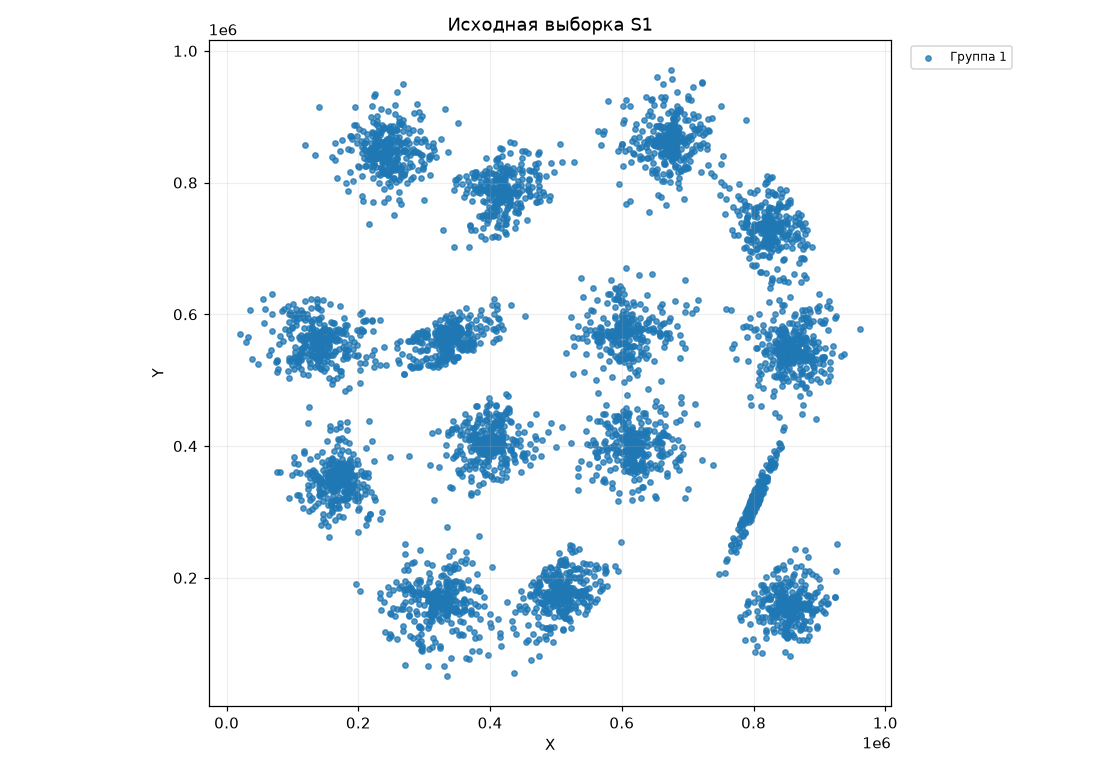

In [3]:
def plot_clusters(points, labels, title, centers=None):
    fig, ax = plt.subplots(figsize=(10, 7))
    unique_labels = np.unique(labels)
    palette = plt.get_cmap("tab20")
    for position, label in enumerate(unique_labels):
        mask = labels == label
        if label == -1:
            ax.scatter(points[mask, 0], points[mask, 1], c="gray", marker="x", s=20, label="Шум (−1)")
        else:
            ax.scatter(points[mask, 0], points[mask, 1], color=palette(position % 20), s=12, alpha=0.75, label=f"Группа {label + 1}")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=100, label="Центроиды", zorder=3)
    ax.set(title=title, xlabel="X", ylabel="Y")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.tight_layout()
    plt.show()

plot_clusters(X, np.zeros(len(X), dtype=int), "Исходная выборка S1")

## KMeans
Ищет 15 центров, минимизируя сумму квадратов расстояний до них. `n_init=10` — десять запусков; `random_state=42` фиксирует случайную инициализацию.

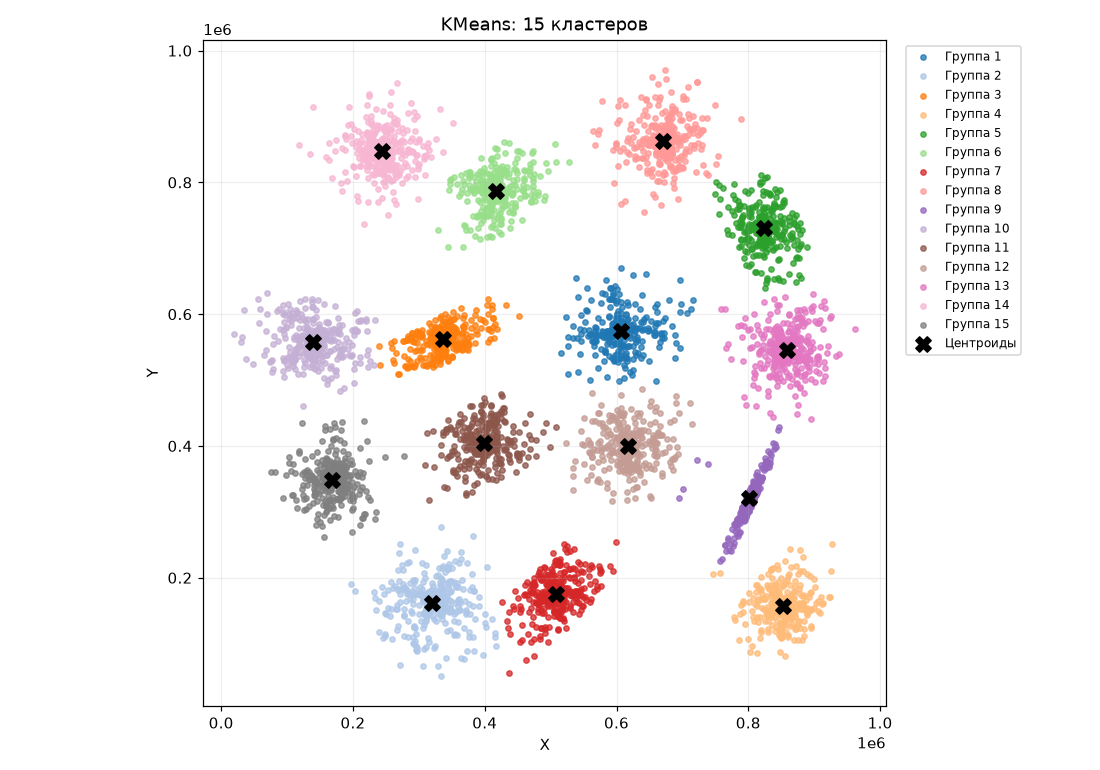

In [4]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
kmeans_labels = kmeans.fit_predict(X)
plot_clusters(X, kmeans_labels, "KMeans: 15 кластеров", centers=kmeans.cluster_centers_)

## Агломеративная кластеризация
Ward объединяет группы с наименьшим приростом внутрикластерного разброса, пока не останется 15 кластеров.

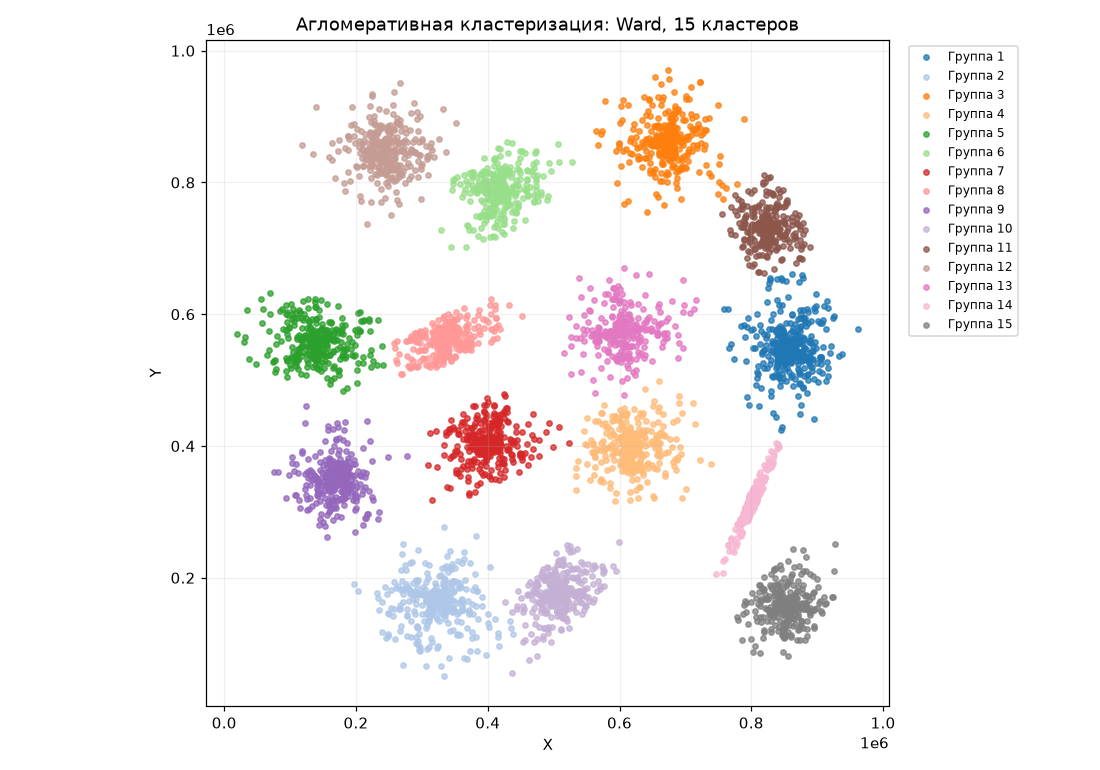

In [5]:
hierarchical = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X)
plot_clusters(X, hierarchical_labels, "Агломеративная кластеризация: Ward, 15 кластеров")

## DBSCAN
Объединяет близкие точки в плотные группы. `eps` — радиус соседства, `min_samples=5` — минимум точек в нём, включая саму точку. Число кластеров напрямую не задаётся: проверяем радиусы и выбираем `eps=20500`, дающий 15 групп. Метка −1 означает шум.

In [6]:
for eps in [15000, 20000, 20500, 22000, 30000]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    cluster_count = len(set(labels) - {-1})
    noise_count = np.sum(labels == -1)
    print(f"eps={eps}: кластеров — {cluster_count}, шумовых точек — {noise_count}")

eps=15000: кластеров — 23, шумовых точек — 333
eps=20000: кластеров — 17, шумовых точек — 152
eps=20500: кластеров — 15, шумовых точек — 140
eps=22000: кластеров — 12, шумовых точек — 110
eps=30000: кластеров — 8, шумовых точек — 37


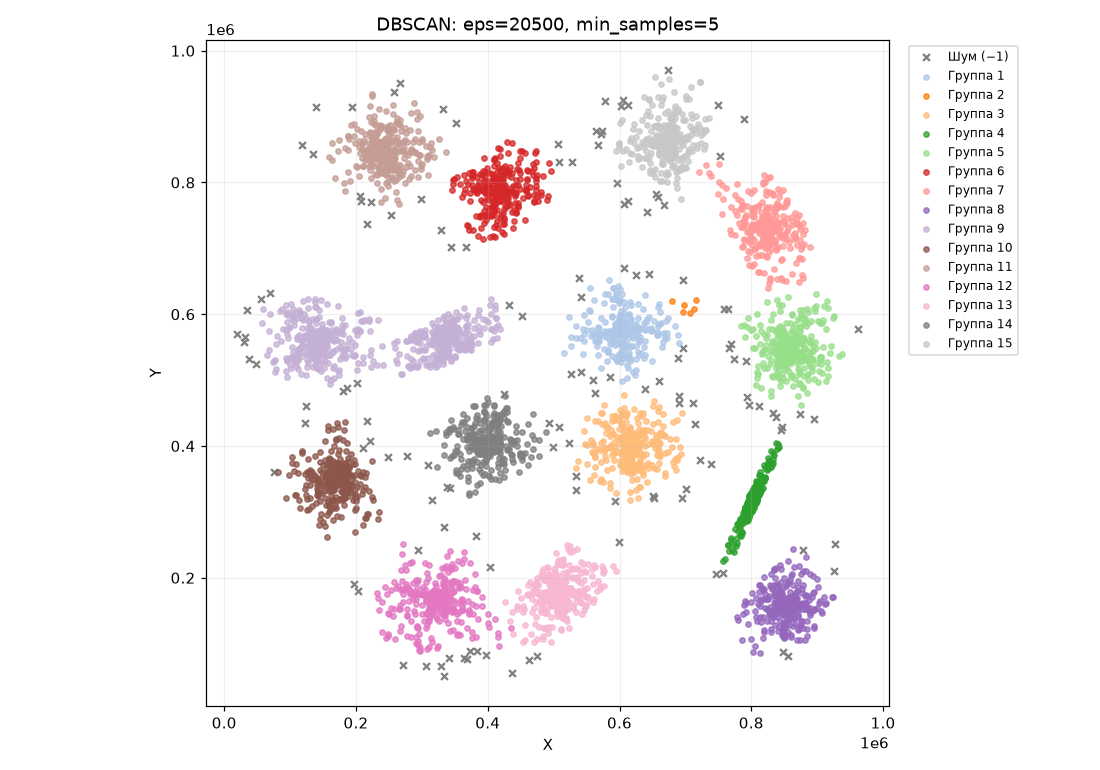

Кластеров: 15
Шумовых точек: 140


In [7]:
dbscan = DBSCAN(eps=20500, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)
plot_clusters(X, dbscan_labels, "DBSCAN: eps=20500, min_samples=5")
print("Кластеров:", len(set(dbscan_labels) - {-1}))
print("Шумовых точек:", np.sum(dbscan_labels == -1))

## Выводы
Все методы получили 15 кластеров. KMeans и Ward распределили все 5000 точек; DBSCAN выделил 140 шумовых точек (2,8%).

На графиках KMeans и Ward лучше разделяют компактные скопления S1. DBSCAN объединил два соседних скопления и выделил отдельную маленькую группу: одинаковое число кластеров не означает одинаковое разбиение.

KMeans прост, но требует число групп и чувствителен к выбросам. Ward позволяет строить иерархию, но затратнее на больших выборках. DBSCAN выделяет шум и группы сложной формы, однако чувствителен к радиусу соседства и разной плотности данных.